# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

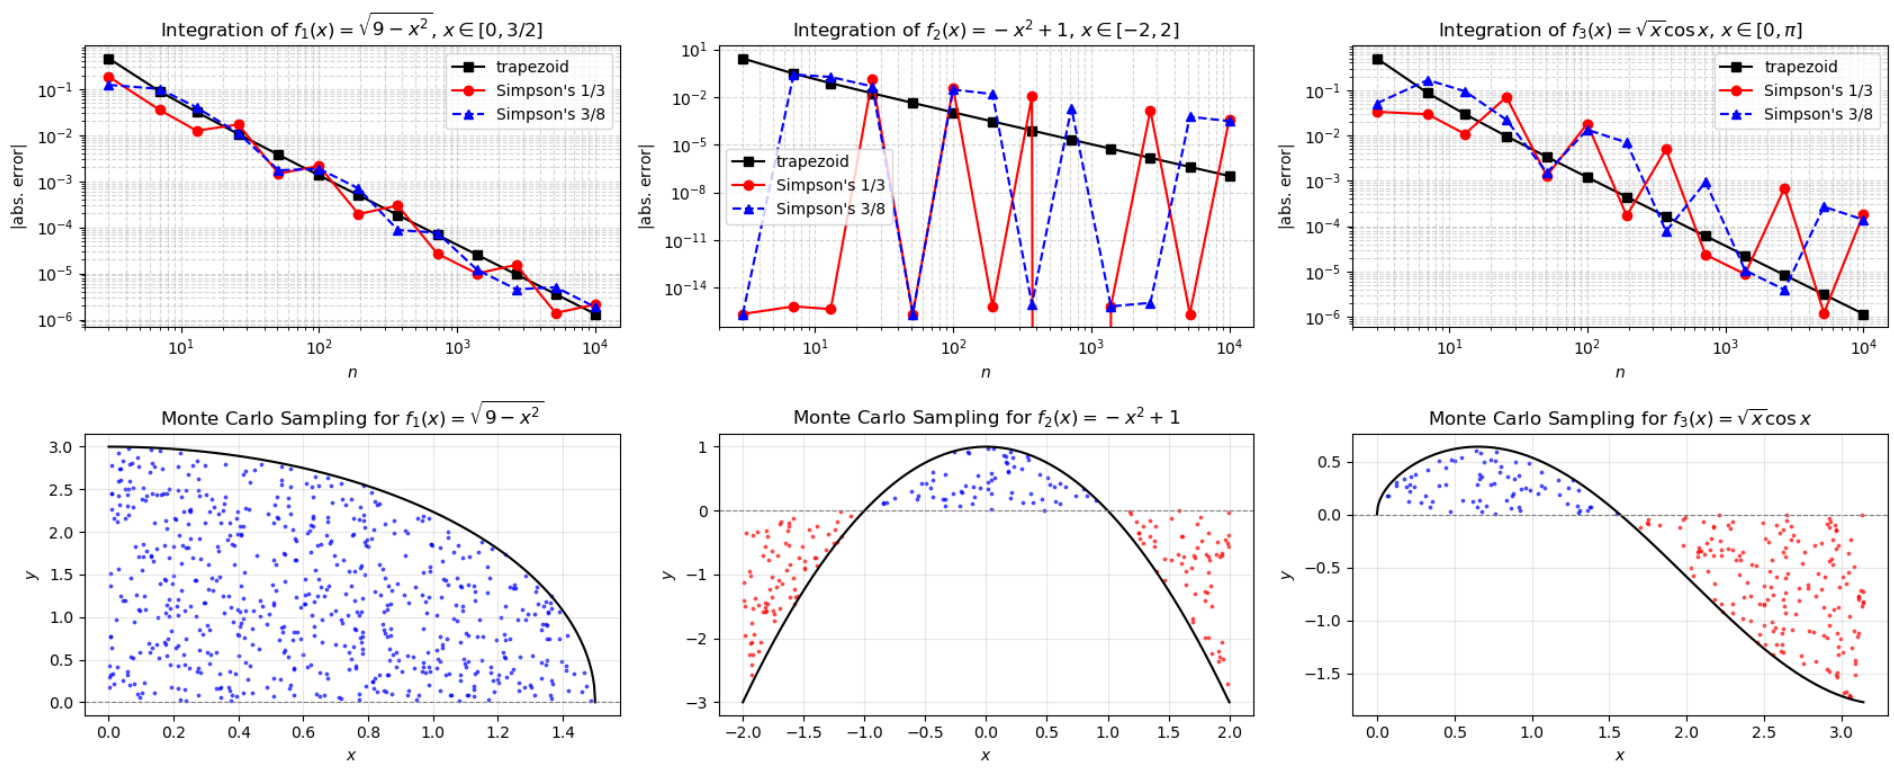 


Figure 1. Absolute error of each methods and Monte Carlo integration for three different functions.


### Report discussion

The top figures show the the number of points $n$ vs the absolute error $I_{numerical} - I_{true}$ for the three different numerical integration, namely the Trapezoidal, Simpson's 1/3, and Simpson's 3/8 rules. 

As seen in $f_1(x)$ integration, all methods are very close to each other, the errors decreasing monotonically as $n$ gets larger. A similar trend is also seen in $f_3(x)$, but less precise relative to the first function. For $f_2(x)$, the Simpson's rule method and its error went up and down blowing the precision.

The bottom figures show the Monte Carlo sampling plots for each function $f_i(x)$ in their respective domain $[a,b]$. The functions are in black, and those red and blue are random points. Red is for points in regative regions, and blue is for posibit regions. The density and ration of these points show the area under the curve.

With the Monte Carlo integration, we can get the value of an integral via the law of large numbers, done statistically, it is where the sample random points' mean converges to the expected value.

The Newton-Cotes methods are best utilized for 1d-3d problems that require rapid, high-precision deterministic convergence. On the other hand, Monte Carlo is probabilistic and inefficient for low dimensions but very useful in higher dimensions.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.integrate import quad
import scipy.special as special

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



I_scipy_f1 = 3.534291735288518
error_f1 = 5.742084585591556e-11
I_scipy_f2 = -1.3333333333333335
error_f2 = 4.465845366792915e-14
I_scipy_f3 = -0.8948314694841447
error_f3 = 5.742084585591556e-11
I_trapezoidal_f1 = 3.5342498374451385
I_trapezoidal_f2 = -1.3333440213653758
I_trapezoidal_f3 = -0.8948683627997766
I_simpson13_f1 = 3.5342243029391165
I_simpson13_f2 = -1.3293400173613719
I_simpson13_f3 = -0.8929882840684703
I_simpson38_f1 = 3.5342325866032858
I_simpson38_f2 = -1.330341336
I_simpson38_f3 = -0.8934571396825032


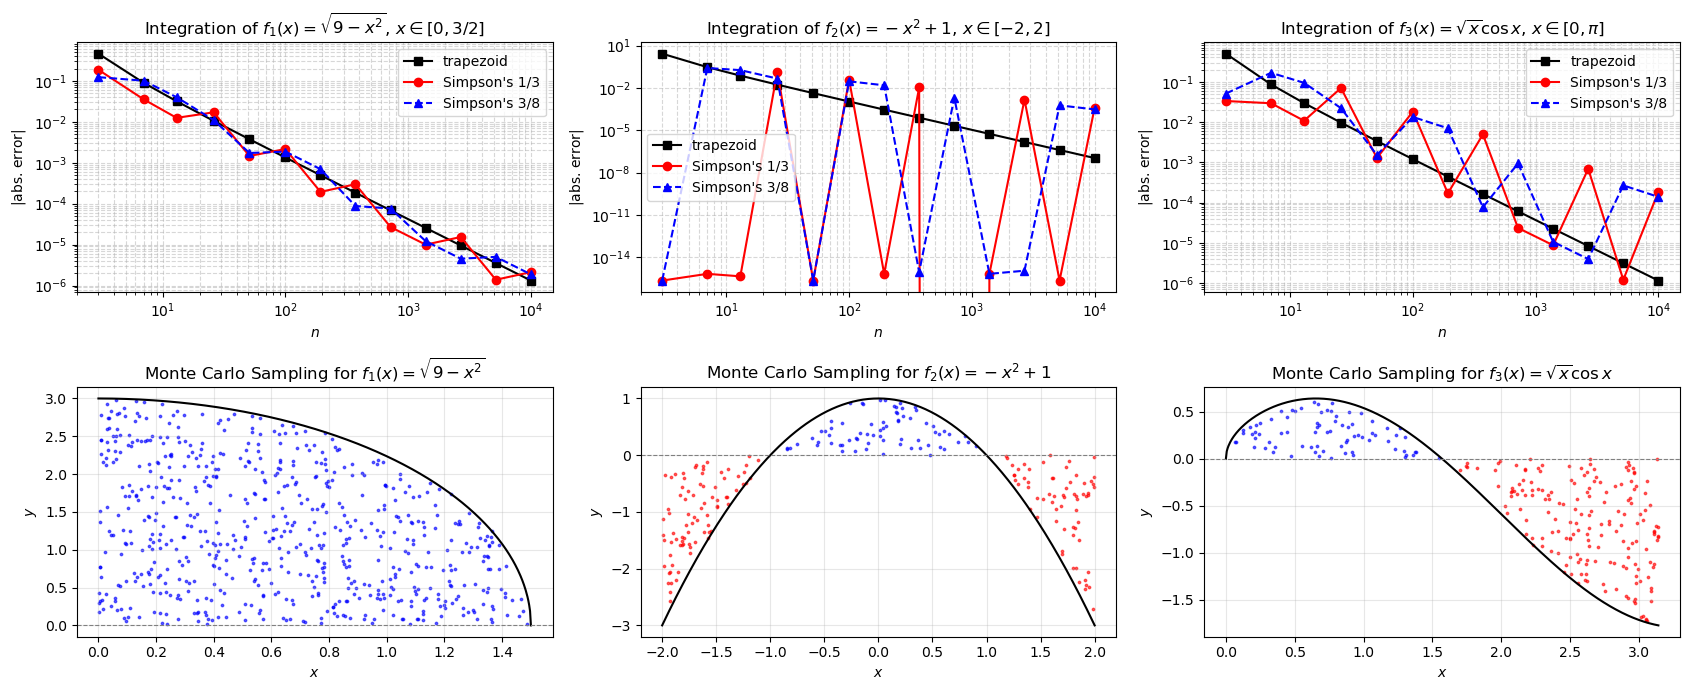

In [29]:
#functions given
def f1(x):
    return np.sqrt(np.maximum(0, 9 - 4 * x**2))
def f2(x):
    return -x**2 + 1
def f3(x):
    return np.sqrt(x)*np.cos(x)

#scipy,integrate.quad, quad = 1D int.
I_scipy_f1, error_f1 = quad(f1, 0, 3/2)
print(f"I_scipy_f1 = {I_scipy_f1}")
print(f"error_f1 = {error}")

I_scipy_f2, error = quad(f2, -2, 2)
print(f"I_scipy_f2 = {I_scipy_f2}")
print(f"error_f2 = {error}")

I_scipy_f3, error = quad(f3, 0, np.pi)
print(f"I_scipy_f3 = {I_scipy_f3}")
print(f"error_f3 = {error}")

#trapezoidal integration
def trapezoidal(f,a,b,n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    contributions = cs*f(xs)
    return h*np.sum(contributions)

#simpson's rule 1/3 integration
def simpson13(f,a,b,n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contributions = cs*f(xs)
    return (h/3)*np.sum(contributions)

#simpson's rule 3/8 integration
def simpson38(f,a,b,n):
    h = (b - a)/n
    xs = np.linspace(a, b, n + 1)
    y = f(xs)
    sum_mult_3 = np.sum(y[3:-1:3])
    sum_remain = np.sum(y[1:-1]) - sum_mult_3
    return (3*h/8)*(y[0] + 3*sum_remain + 2*sum_mult_3 + y[-1])
    
#define test functions and their bounds together
test_cases = [('f1', f1, 0, 3 / 2), ('f2', f2, -2, 2), ('f3', f3, 0, np.pi)]

#loop through each integrator and test case
for integrator in (trapezoidal, simpson13, simpson38):
  for name, f, a, b in test_cases:
    result = integrator(f, a, b, 1000)
    print(f'I_{integrator.__name__}_{name} = {result}')

ns = np.unique(np.logspace(0, 4, 15).astype(int))
ns = ns[ns > 1]  #filters out n = 1

#compute errors across all n for each method
#f1
f1_err_trapezoid = [np.abs(trapezoidal(f1, 0, 3/2, n) - I_scipy_f1) for n in ns]
f1_err_simpson13 = [np.abs(simpson13(f1, 0, 3/2, n) - I_scipy_f1) for n in ns]
f1_err_simpson38 = [np.abs(simpson38(f1, 0, 3/2, n) - I_scipy_f1) for n in ns]

#f2
f2_err_trapezoid = [np.abs(trapezoidal(f2, -2, 2, n) - I_scipy_f2) for n in ns]
f2_err_simpson13 = [np.abs(simpson13(f2, -2, 2, n) - I_scipy_f2) for n in ns]
f2_err_simpson38 = [np.abs(simpson38(f2, -2, 2, n) - I_scipy_f2) for n in ns]

#f3
f3_err_trapezoid = [np.abs(trapezoidal(f3, 0, np.pi, n) - I_scipy_f3) for n in ns]
f3_err_simpson13 = [np.abs(simpson13(f3, 0, np.pi, n) - I_scipy_f3) for n in ns]
f3_err_simpson38 = [np.abs(simpson38(f3, 0, np.pi, n) - I_scipy_f3) for n in ns]

#Monte Carlo
MC_Npoints = 1000

#f1
x_MC1 = np.random.uniform(0, 3/2, MC_Npoints)
x_dense1 = np.linspace(0, 3/2, 500)
y_dense1 = f1(x_dense1)
y_min1, y_max1 = min(0, np.min(y_dense1)), max(0, np.max(y_dense1))
y_padding1 = (y_max1 - y_min1) * 0.1 if y_max1 != y_min1 else 1.0
y_MC1 = np.random.uniform(y_min1 - y_padding1, y_max1 + y_padding1, MC_Npoints)
f_val1 = f1(x_MC1)

blue_mask1 = (y_MC1 >= 0) & (y_MC1 <= f_val1)
red_mask1 = (y_MC1 <= 0) & (y_MC1 >= f_val1)

#f2
x_MC2 = np.random.uniform(-2, 2, MC_Npoints)
x_dense2 = np.linspace(-2, 2, 500)
y_dense2 = f2(x_dense2)
y_min2, y_max2 = min(0, np.min(y_dense2)), max(0, np.max(y_dense2))
y_padding2 = (y_max2 - y_min2) * 0.1 if y_max2 != y_min2 else 1.0
y_MC2 = np.random.uniform(y_min2 - y_padding2, y_max2 + y_padding2, MC_Npoints)
f_val2 = f2(x_MC2)

blue_mask2 = (y_MC2 >= 0) & (y_MC2 <= f_val2)
red_mask2 = (y_MC2 <= 0) & (y_MC2 >= f_val2)

#f3
x_MC3 = np.random.uniform(0, np.pi, MC_Npoints)
x_dense3 = np.linspace(0, np.pi, 500)
y_dense3 = f3(x_dense3)
y_min3, y_max3 = min(0, np.min(y_dense3)), max(0, np.max(y_dense3))
y_padding3 = (y_max3 - y_min3) * 0.1 if y_max3 != y_min3 else 1.0
y_MC3 = np.random.uniform(y_min3 - y_padding3, y_max3 + y_padding3, MC_Npoints)
f_val3 = f3(x_MC3)

blue_mask3 = (y_MC3 >= 0) & (y_MC3 <= f_val3)
red_mask3 = (y_MC3 <= 0) & (y_MC3 >= f_val3)

#plots
fig, axs = plt.subplots(2, 3, figsize=(17, 7))

#Trapezoidal, Simpson's plot
axs[0, 0].loglog(ns, f1_err_trapezoid, 's-', label='trapezoid', color='black')
axs[0, 0].loglog(ns, f1_err_simpson13, 'o-', label="Simpson's 1/3", color='red')
axs[0, 0].loglog(ns, f1_err_simpson38, '^--', label="Simpson's 3/8", color='blue')
axs[0, 0].set_title(r'Integration of $f_1(x) = \sqrt{9-x^2}$, $x\in[0, 3/2]$')
axs[0, 0].set_xlabel('$n$')
axs[0, 0].set_ylabel(r'$\vert\text{abs. error}\vert$')
axs[0, 0].grid(True, which='both', linestyle='--', alpha=0.5)
axs[0, 0].legend()

axs[0, 1].loglog(ns, f2_err_trapezoid, 's-', label='trapezoid', color='black')
axs[0, 1].loglog(ns, f2_err_simpson13, 'o-', label="Simpson's 1/3", color='red')
axs[0, 1].loglog(ns, f2_err_simpson38, '^--', label="Simpson's 3/8", color='blue')
axs[0, 1].set_title(r'Integration of $f_2(x) = -x^2+1$, $x\in[-2, 2]$')
axs[0, 1].set_xlabel('$n$')
axs[0, 1].set_ylabel(r'$\vert\text{abs. error}\vert$')
axs[0, 1].grid(True, which='both', linestyle='--', alpha=0.5)
axs[0, 1].legend()

axs[0, 2].loglog(ns, f3_err_trapezoid, 's-', label='trapezoid', color='black')
axs[0, 2].loglog(ns, f3_err_simpson13, 'o-', label="Simpson's 1/3", color='red')
axs[0, 2].loglog(ns, f3_err_simpson38, '^--', label="Simpson's 3/8", color='blue')
axs[0, 2].set_title(r'Integration of $f_3(x) = \sqrt{x}\cos{x}$, $x\in[0, \pi]$')
axs[0, 2].set_xlabel('$n$')
axs[0, 2].set_ylabel(r'$\vert\text{abs. error}\vert$')
axs[0, 2].grid(True, which='both', linestyle='--', alpha=0.5)
axs[0, 2].legend()

#Monte Carlo plot
axs[1, 0].scatter(x_MC1[blue_mask1], y_MC1[blue_mask1], color='blue', s=3, alpha=0.6)
axs[1, 0].scatter(x_MC1[red_mask1], y_MC1[red_mask1], color='red', s=3, alpha=0.6)
axs[1, 0].plot(x_dense1, y_dense1, color='black', linewidth=1.5)
axs[1, 0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axs[1, 0].set_title(r'Monte Carlo Sampling for $f_1(x) = \sqrt{9-x^2}$')
axs[1, 0].set_xlabel('$x$')
axs[1, 0].set_ylabel('$y$')
axs[1, 0].grid(True, alpha=0.3)

axs[1, 1].scatter(x_MC2[blue_mask2], y_MC2[blue_mask2], color='blue', s=3, alpha=0.6)
axs[1, 1].scatter(x_MC2[red_mask2], y_MC2[red_mask2], color='red', s=3, alpha=0.6)
axs[1, 1].plot(x_dense2, y_dense2, color='black', linewidth=1.5)
axs[1, 1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axs[1, 1].set_title(r'Monte Carlo Sampling for $f_2(x) = -x^2+1$')
axs[1, 1].set_xlabel('$x$')
axs[1, 1].set_ylabel('$y$')
axs[1, 1].grid(True, alpha=0.3)

axs[1, 2].scatter(x_MC3[blue_mask3], y_MC3[blue_mask3], color='blue', s=3, alpha=0.6)
axs[1, 2].scatter(x_MC3[red_mask3], y_MC3[red_mask3], color='red', s=3, alpha=0.6)
axs[1, 2].plot(x_dense3, y_dense3, color='black', linewidth=1.5)
axs[1, 2].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axs[1, 2].set_title(r'Monte Carlo Sampling for $f_3(x) = \sqrt{x}\cos{x}$')
axs[1, 2].set_xlabel('$x$')
axs[1, 2].set_ylabel('$y$')
axs[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()